# Titanic Prediction Project

In [1]:
import pandas as pd
import numpy as np

import matplotlib as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### What is the majority class of Survived?

In [5]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [6]:
actual = train['Survived']
prediction = np.zeros(len(train))
accuracy_score(actual, prediction)

0.6161616161616161

### Survived Rate by Sex

In [7]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

**Insight:** Female have a higher survival chance compared to male.

### Survival Rate by Pclass

In [8]:
train.groupby('Pclass', as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


### Survived data by Sex and Pclass

In [9]:
train.groupby(['Sex', 'Pclass'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

### Survival Rate by Title, create Title column

In [10]:
train['Title'] = train['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
test['Title'] = test['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
train.groupby(['Title'], as_index=False)['Survived'].agg(['mean', 'count'])

,Title,mean,count
0,Capt,0.000000,1
1,Col,0.500000,2
2,Don,0.000000,1
3,Dr,0.428571,7
4,Jonkheer,0.000000,1
5,Lady,1.000000,1
6,Major,0.500000,2
7,Master,0.575000,40
8,Miss,0.697802,182
9,Mlle,1.000000,2


**Insights:** Based on the count of these titles do grouping.

In [11]:
for df in [train, test]:
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

train.groupby('Title')['Survived'].agg(['mean', 'count'])

,mean,count
Title,,
Master,0.575000,40
Miss,0.702703,185
Mr,0.156673,517
Mrs,0.793651,126
Rare,0.347826,23


### Age Distribution by Survival

<Axes: xlabel='Age', ylabel='Count'>

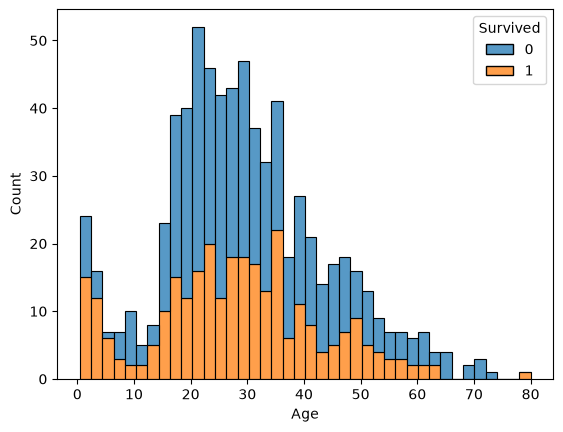

In [12]:
sns.histplot(data=train, x='Age', hue='Survived', bins = 40, multiple='stack')

**Insight:** Most passengers's age is between 20 and 36, but this group is too small which will shrinks the groups with other conditions.

### Survival Rate and Count by Embarked

In [13]:
train.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644


### Survived data by Sex, Pclass, and Embarked

In [14]:
train.groupby(['Sex', 'Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass Embarked                 
female 1      C         0.976744     43
              Q         1.000000      1
              S         0.958333     48
       2      C         1.000000      7
              Q         1.000000      2
              S         0.910448     67
       3      C         0.652174     23
              Q         0.727273     33
              S         0.375000     88
male   1      C         0.404762     42
              Q         0.000000      1
              S         0.354430     79
       2      C         0.200000     10
              Q         0.000000      1
              S         0.154639     97
       3      C         0.232558     43
              Q         0.076923     39
              S         0.128302    265

**Insight:** Passenger who is Female, Pclass is 1 or 2 is having a very high survival mean. Beside the female that embarked S, female in third class don't have a low survival mean compared to male.

### Predict it with the patterns from the "Insight" above

In [15]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & ~((train['Pclass'] == 3) & (train['Embarked'] == 'S'))).astype(int)

accuracy_score(actual, prediction)

0.8114478114478114

### Predict it with Female and first class

In [16]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & (train['Pclass'] == 1)).astype(int)

accuracy_score(actual, prediction)

0.7149270482603816

**Insight:** The "Insight" patterns have a better accuracy score compared to this.

### Rule-based Classifier: Apply the patterns from "Insight" on the test dataframe as well

Rules applied: All the female besides those are both 3rd class and Embarked S.

In [17]:
test['Survived'] = ((test['Sex'] == 'female') & ~((test['Pclass'] == 3) & (test['Embarked'] == 'S'))).astype(int)


In [18]:
final_prediction = test[['PassengerId', 'Survived']]
final_prediction.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [19]:
final_prediction.to_csv('ian_prediction.csv', index=False)

**Insight:** The rule( All the famle besides those are both 3rd class and Embarked S)'s score: 0.77844 is greater than the baseline(0.75). It built by hand from patterns I found.

## Modeling

Try to improve the prediction by machine-learning models:

### Feature engineering

Check if there is any null value in the data.

In [20]:
print(train.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
Title            0
dtype: int64


In [21]:
print(test.isnull().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
Title            0
Survived         0
dtype: int64


Only use the features that might show clear survival differences.
Create the Family Size feature, including the passenger too.
Fill the missing values for Fare and Age with median.
Convert text columns to numbers for modeling.

In [22]:
def preprocess(df):
    X = pd.DataFrame(index=df.index)
    X['Pclass'] = df['Pclass']
    X['Sex'] = (df['Sex']=='female').astype(int)
    X['Age'] = df['Age'].fillna(train['Age'].median())
    X['SibSp'] = df['SibSp']
    X['Parch'] = df['Parch']
    X['Fare'] = df['Fare'].fillna(train['Fare'].median())
    X['Embarked_C'] = (df['Embarked']=='C').astype(int)
    X['Embarked_Q'] = (df['Embarked']=='Q').astype(int)
    X['Fam_Size'] = df['SibSp'] + df['Parch'] + 1
    for i in ['Mr', 'Mrs', 'Miss', 'Master']:
        X['Title:' + i] = (df['Title']==i).astype(int)

    return X

X, y, X_test = preprocess(train), train['Survived'], preprocess(test)
print(X.shape, X_test.shape)
print(X.isnull().sum())
print(X_test.isnull().sum())

(891, 13) (418, 13)
Pclass          0
Sex             0
Age             0
SibSp           0
Parch           0
Fare            0
Embarked_C      0
Embarked_Q      0
Fam_Size        0
Title:Mr        0
Title:Mrs       0
Title:Miss      0
Title:Master    0
dtype: int64
Pclass          0
Sex             0
Age             0
SibSp           0
Parch           0
Fare            0
Embarked_C      0
Embarked_Q      0
Fam_Size        0
Title:Mr        0
Title:Mrs       0
Title:Miss      0
Title:Master    0
dtype: int64


### Cross-validation Preparing

In [23]:
from sklearn.model_selection import cross_validate

results = {}
def evaluate(name, model):
    scores = cross_validate(model, X, y, cv=5, return_train_score=True)
    cv_acc = scores['test_score'].mean()
    gap = scores['train_score'].mean() - cv_acc
    results[name] = {'cv': cv_acc, 'gap': gap}
    print(name, 'cv:', round(cv_acc, 4), 'gap:', round(gap, 4))

cv is the average accuracy. Keeping tracking the gap(training accuracy - cv) to avoid overfitting.

### Models Comparing

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

models_n = {
    'Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(31, ), max_iter=1000, early_stopping=True, solver='adam', random_state=42))
}

for name, model in models_n.items():
    evaluate(name, model)

Tree cv: 0.8069 gap: 0.0696
LogRe cv: 0.8249 gap: 0.0067
MLP cv: 0.8081 gap: 0.0171


**Insight:** Decision Tree have the highest cv but it is having the large gap too.

## Ensemble Models / Methods:

### Simple Combination

In [25]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(list(models_n.items()), voting='soft')
evaluate('Voting', voting_model)

Voting cv: 0.8227 gap: 0.0368


### Bagging & Random Forest

In [26]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6, random_state=42), n_estimators=200, random_state=42)

random_forest = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)

evaluate('Bagging', bagging_model)
evaluate('Random Forest', random_forest)

Bagging cv: 0.8328 gap: 0.0643
Random Forest cv: 0.8215 gap: 0.0415


### Boosting

In [27]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42)
evaluate('Ada_Boosted', ada_model)

Ada_Boosted cv: 0.8215 gap: 0.0093


### Stacking

In [28]:
from sklearn.ensemble import StackingClassifier

stack_model = StackingClassifier(
    estimators=[
        ('LogRe', models_n['LogRe']),
        ('Random Forest', random_forest),
        ('MLP', models_n['MLP']),
        ('Ada_Boosted', ada_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

evaluate('Stacking', stack_model)

Stacking cv: 0.8272 gap: 0.0205


In [29]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
Bagging,0.832760,0.064268
Stacking,0.827155,0.020489
LogRe,0.824914,0.006737
Voting,0.822666,0.036761
Random Forest,0.821543,0.041534
Ada_Boosted,0.821537,0.009270
MLP,0.808116,0.017078
Tree,0.806930,0.069614


**Insight:** I will choose Stacking model because it have a high cv but its gap is much smaller than Bagging model.

## Final Model for Submission

In [30]:
final_model = stack_model
final_model.fit(X, y)

final_submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': final_model.predict(X_test)})
final_submission.to_csv('ian_final_prediction.csv', index=False)
final_submission['Survived'].value_counts()

Survived
0    255
1    163
Name: count, dtype: int64

## Submission without Title

In [31]:
from sklearn.base import clone

def preprocess_no_title(df):
    X = preprocess(df).drop(columns=['Title:Mr', 'Title:Mrs', 'Title:Miss', 'Title:Master'])
    return X

X_nt, X_test_nt = preprocess_no_title(train), preprocess_no_title(test)
stack_no_title = clone(stack_model).fit(X_nt, y)

no_title_submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': stack_no_title.predict(X_test_nt)})
no_title_submission.to_csv('ian_final_prediction_no_title.csv', index=False)
no_title_submission['Survived'].value_counts()

Survived
0    272
1    146
Name: count, dtype: int64